In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt


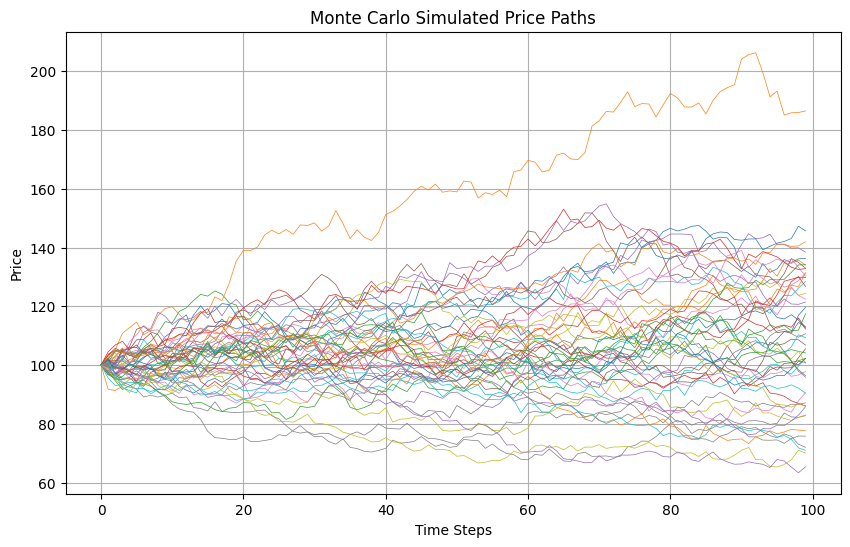

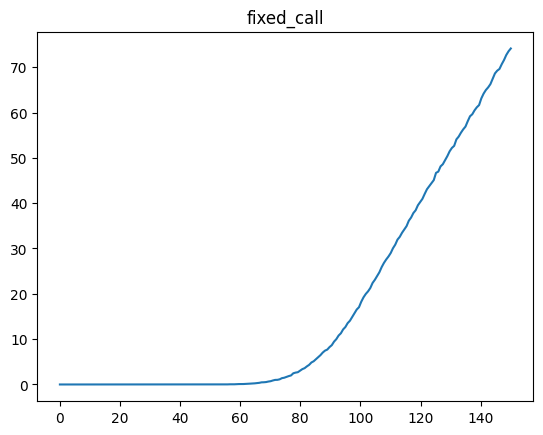

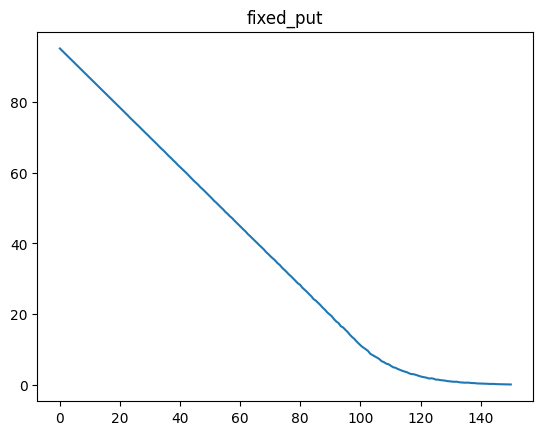

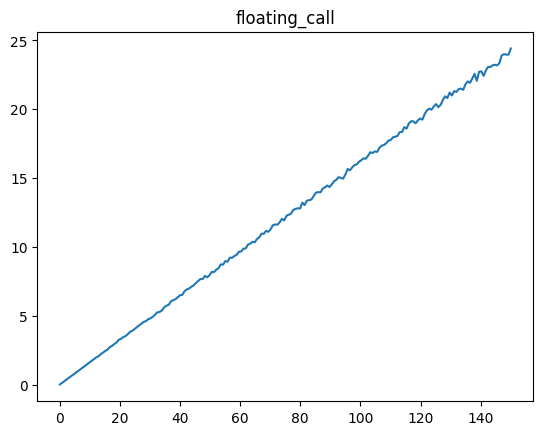

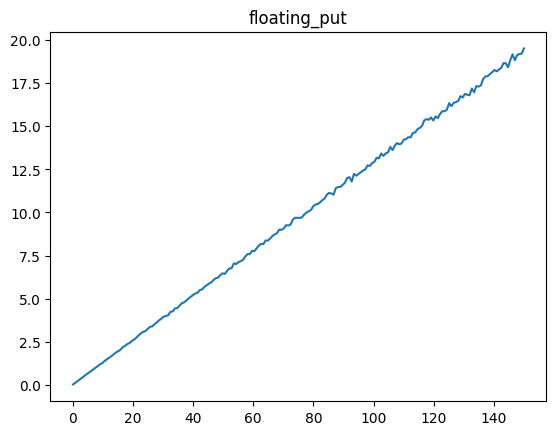

Monte Carlo Fixed Call Price: 17.927854537963867
Monte Carlo Fixed Put Price: 11.429813385009766


In [ ]:
# Data type
DTYPE = 'float32'
tf.keras.backend.set_floatx(DTYPE)

# Parameters
T = tf.constant(1.0, dtype=DTYPE)  # Maturity
r = tf.constant(0.05, dtype=DTYPE)  # Risk-free rate
sigma = tf.constant(0.2, dtype=DTYPE)  # Volatility
K = tf.constant(100.0, dtype=DTYPE)  # Strike price

# Monte Carlo simulation for option pricing

    # Perform Monte Carlo simulation to estimate the price of Lookback Options.

    # Parameters:
    #     S0 (float): Initial price of the underlying asset.
    #     option_type (str): Type of the option ('fixed_call', 'fixed_put', 'floating_call', 'floating_put').
    #     num_simulations (int): Number of simulated price paths.
    #     num_steps (int): Number of time steps in each simulation.

    # Returns:
    #     option_price (float): Estimated price of the option.
    #     S_paths (tf.Tensor): Simulated price paths of the underlying asset.

def monte_carlo_simulation(S0, option_type='fixed_call', num_simulations=10000, num_steps=100):
    S0_mat = tf.constant(S0, shape=(num_simulations, 1), dtype=DTYPE)
    #print(S0_mat)
    dt = T / num_steps
    S_paths = [S0_mat]

    for _ in range(num_steps - 1):
        dW = tf.random.normal(shape=(num_simulations, 1), mean=0.0, stddev=tf.sqrt(dt), dtype=DTYPE)
        S_next = S_paths[-1] * tf.exp((r - 0.5 * sigma**2) * dt + sigma * dW)
        S_paths.append(S_next)

    S_paths = tf.concat(S_paths, axis=1)
    min_S = tf.reduce_min(S_paths, axis=1, keepdims=True)
    max_S = tf.reduce_max(S_paths, axis=1, keepdims=True)
    S_T = S_paths[:, -1:]

    if option_type == 'fixed_call':
        payoff = tf.maximum(max_S - K, 0.0)
    elif option_type == 'fixed_put':
        payoff = tf.maximum(K - min_S, 0.0)
    elif option_type == 'floating_call' :
        payoff = tf.maximum(S_T - min_S, 0.0)
    elif option_type == 'floating_put' :
        payoff = tf.maximum(max_S - S_T, 0.0)
    else:
        raise ValueError("Invalid option type")

    option_price = tf.reduce_mean(payoff) * tf.exp(-r * T)
    #print(option_price)
    return option_price.numpy(), S_paths

# Test Monte Carlo simulation
fixed_call_price, fixed_call_paths = monte_carlo_simulation(100,option_type='fixed_call')
fixed_put_price, fixed_put_paths = monte_carlo_simulation(100,option_type='fixed_put')

# Visualize price paths
plt.figure(figsize=(10, 6))
for i in np.arange(0,50):  # Plot 10 paths
    plt.plot(fixed_call_paths[i], lw=0.5)
plt.title('Monte Carlo Simulated Price Paths')
plt.xlabel('Time Steps')
plt.ylabel('Price')
plt.grid()
plt.show()

# Visualize call option price at t=0
S0 = np.linspace(0.1,150,200)
for tmp_type in ['fixed_call','fixed_put','floating_call','floating_put'] :
    call_price = []
    for S00 in S0 :
        call_price.append(monte_carlo_simulation(S00,option_type=tmp_type)[0])
        #print(monte_carlo_simulation(S00,option_type='fixed_call')[0])
    plt.plot(S0,call_price)
    plt.title(tmp_type)
    plt.show()

# Display Monte Carlo prices
print(f"Monte Carlo Fixed Call Price: {fixed_call_price}")
print(f"Monte Carlo Fixed Put Price: {fixed_put_price}")

In [ ]:

# Set data type
DTYPE = 'float32'
tf.keras.backend.set_floatx(DTYPE)

# Define parameters
T = tf.constant(2.0, dtype=DTYPE)  # Maturity time
r = tf.constant(0.05, dtype=DTYPE)  # Interest rate
sigma = tf.constant(0.2, dtype=DTYPE)  # Volatility
K = tf.constant(100.0, dtype=DTYPE)  # Strike price
a = tf.constant(75.0, dtype=DTYPE)  # Lower bound for asset price
b = tf.constant(125.0, dtype=DTYPE)  # Upper bound for asset price


# Payoff functions
def fixed_call_payoff(S_paths):
    max_S = tf.reduce_max(S_paths, axis=1, keepdims=True)  # Minimum asset price
    payoff = tf.maximum(max_S-K, 0.0)
    return tf.tile(payoff, [1, S_paths.shape[1]])  # Match time_steps dimension

def fixed_put_payoff(S_paths):
    min_S = tf.reduce_min(S_paths, axis=1, keepdims=True)  # Minimum asset price
    payoff = tf.maximum(K-min_S, 0.0)
    return tf.tile(payoff, [1, S_paths.shape[1]])  # Match time_steps dimension

def floating_call_payoff(S_paths):
    min_S = tf.reduce_min(S_paths, axis=1, keepdims=True)  # Minimum asset price
    payoff = tf.maximum(S_paths[:, -1:] - min_S, 0.0)
    return tf.tile(payoff, [1, S_paths.shape[1]])  # Match time_steps dimension

def floating_put_payoff(S_paths):
    max_S = tf.reduce_max(S_paths, axis=1, keepdims=True)  # Minimum asset price
    payoff = tf.maximum(max_S-S_paths[:, -1:], 0.0)
    return tf.tile(payoff, [1, S_paths.shape[1]])  # Match time_steps dimension

# Generate paths
def generate_paths(batch_size, time_steps):
    S0 = tf.random.uniform((batch_size, 1), minval=a, maxval=b, dtype=DTYPE)  # Initial asset price
    dt = T / time_steps
    paths = [S0]
    for _ in range(1, time_steps):
        dW = tf.random.normal((batch_size, 1), mean=0.0, stddev=tf.sqrt(dt), dtype=DTYPE)
        St = paths[-1] * tf.exp((r - 0.5 * sigma**2) * dt + sigma * dW)
        paths.append(St)
    return tf.concat(paths, axis=1)  # Shape: (batch_size, time_steps)

# Define model
def init_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(3,)),
        tf.keras.layers.Dense(50, activation='tanh'),
        tf.keras.layers.Dense(50, activation='tanh'),
        tf.keras.layers.Dense(50, activation='tanh'),
        tf.keras.layers.Dense(1, activation=None)
    ])
    return model

# PDE and loss

@tf.function
def loss_function(model, S, M, t, payoff):
    with tf.GradientTape(persistent=True) as tape:
        tape.watch([S, M, t])
        inputs = tf.concat([S, M, t], axis=1)  # Combine S, M, and t into a single input tensor
        u = model(inputs)  # Model output

        # Compute gradients
        u_S = tape.gradient(u, S)
        u_M = tape.gradient(u, M)
        u_t = tape.gradient(u, t)

    # Second-order derivative w.r.t. S
    u_SS = tape.gradient(u_S, S)

    # PDE loss calculation
    pde_residual = u_t + 0.5 * sigma**2 * S**2 * u_SS + r * S * u_S - r * u
    loss_pde = tf.reduce_mean(tf.square(pde_residual))

    # Reshape payoff to match output
    payoff = tf.reshape(payoff, (-1, 1))
    #tmp_payoff = payoff[:,-1]
    mask = tf.equal(t, T)  # Create a mask where t == T
    aa = tf.boolean_mask(tf.square(u-payoff), mask)  # Filter u for t == T
    loss_payoff = tf.reduce_mean(aa)

    # Neumann boundary condition: dV/dM = 0 when M ≈ S for all t
    mask = tf.equal(M, S)
    u_M_at_mask = tf.boolean_mask(u_M, mask)
    loss_Neumann = tf.reduce_mean(tf.square(u_M_at_mask))



    # Total loss
    total_loss = loss_pde + loss_payoff + loss_Neumann

    return total_loss


#--------- --------------

import matplotlib.pyplot as plt

# Training loop with loss tracking
def train_pinn_with_plot(model, payoff_function, epochs=5000, batch_size=2000, time_steps=100):
    optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
    losses = []  # Store loss values for plotting

    for epoch in range(epochs):
        S_paths = generate_paths(batch_size, time_steps)  # Generate paths
        t = tf.linspace(0.0, T, time_steps)  # Generate time steps
        t = tf.tile(t[tf.newaxis, :], [batch_size, 1])  # Tile for batch size
        payoff = payoff_function(S_paths)  # Compute payoff

        # Cumulative minimum (M)
        M = tf.TensorArray(dtype=S_paths.dtype, size=S_paths.shape[1])
        current_min = S_paths[:, 0]
        M = M.write(0, current_min)
        for i in range(1, S_paths.shape[1]):
            current_min = tf.minimum(current_min, S_paths[:, i])
            M = M.write(i, current_min)
        M = M.stack()
        M = tf.transpose(M)

        S = tf.reshape(S_paths, (-1, 1))  # Flatten S_paths
        t = tf.reshape(t, (-1, 1))  # Flatten time steps
        M = tf.reshape(M, (-1, 1))  # Flatten M

        with tf.GradientTape() as tape:
            loss = loss_function(model, S, M, t, payoff)
        gradients = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(gradients, model.trainable_variables))

        losses.append(loss.numpy())  # Save loss for plotting

        if epoch % 100 == 0 or epoch == epochs - 1:
            print(f"Epoch {epoch}, Loss: {loss.numpy()}")

    # Plot the loss values
    plt.plot(range(epochs), losses, label="Training Loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.title("Training Loss over Epochs")
    plt.legend()
    plt.show()

    # Generate and plot option prices
    S_paths = generate_paths(1000, time_steps)  # Generate paths for plotting
    payoff = payoff_function(S_paths)
    plt.hist(payoff[:, -1].numpy(), bins=50, alpha=0.7, label="Option Prices")
    plt.xlabel("Option Price")
    plt.ylabel("Frequency")
    plt.title("Distribution of Option Prices (Fixed Call)")
    plt.legend()
    plt.show()

model = init_model()
train_pinn_with_plot(model, fixed_call_payoff, epochs=20000, batch_size=1000, time_steps=50)


Epoch 0, Loss: 1631.6160888671875
Epoch 100, Loss: 1374.1497802734375
Epoch 200, Loss: 987.5164184570312
Epoch 300, Loss: 1087.5350341796875
Epoch 400, Loss: 810.334716796875
Epoch 500, Loss: 781.2785034179688
Epoch 600, Loss: 587.3523559570312
Epoch 700, Loss: 557.0752563476562
Epoch 800, Loss: 515.129150390625
Epoch 900, Loss: 453.3379211425781
Epoch 1000, Loss: 472.83575439453125
Epoch 1100, Loss: 288.3558654785156
Epoch 1200, Loss: 343.73492431640625
Epoch 1300, Loss: 309.1117248535156
Epoch 1400, Loss: 266.7988586425781
Epoch 1500, Loss: 225.52340698242188
Epoch 1600, Loss: 280.5132751464844
Epoch 1700, Loss: 239.33233642578125
Epoch 1800, Loss: 227.22494506835938
Epoch 1900, Loss: 196.7720489501953
Epoch 2000, Loss: 148.3290252685547
Epoch 2100, Loss: 200.01193237304688
Epoch 2200, Loss: 183.95135498046875
Epoch 2300, Loss: 145.04176330566406
Epoch 2400, Loss: 176.32424926757812
Epoch 2500, Loss: 197.22384643554688
Epoch 2600, Loss: 155.75955200195312
Epoch 2700, Loss: 131.638595

In [ ]:

# Set data type
DTYPE = 'float32'
tf.keras.backend.set_floatx(DTYPE)

# Define parameters
T = tf.constant(2.0, dtype=DTYPE)  # Maturity time
r = tf.constant(0.05, dtype=DTYPE)  # Interest rate
sigma = tf.constant(0.2, dtype=DTYPE)  # Volatility
K = tf.constant(100.0, dtype=DTYPE)  # Strike price
a = tf.constant(75.0, dtype=DTYPE)  # Lower bound for asset price
b = tf.constant(125.0, dtype=DTYPE)  # Upper bound for asset price


# Payoff functions
def fixed_call_payoff(S_paths):
    max_S = tf.reduce_max(S_paths, axis=1, keepdims=True)  # Minimum asset price
    payoff = tf.maximum(max_S-K, 0.0)
    return tf.tile(payoff, [1, S_paths.shape[1]])  # Match time_steps dimension

def fixed_put_payoff(S_paths):
    min_S = tf.reduce_min(S_paths, axis=1, keepdims=True)  # Minimum asset price
    payoff = tf.maximum(K-min_S, 0.0)
    return tf.tile(payoff, [1, S_paths.shape[1]])  # Match time_steps dimension

def floating_call_payoff(S_paths):
    min_S = tf.reduce_min(S_paths, axis=1, keepdims=True)  # Minimum asset price
    payoff = tf.maximum(S_paths[:, -1:] - min_S, 0.0)
    return tf.tile(payoff, [1, S_paths.shape[1]])  # Match time_steps dimension

def floating_put_payoff(S_paths):
    max_S = tf.reduce_max(S_paths, axis=1, keepdims=True)  # Minimum asset price
    payoff = tf.maximum(max_S-S_paths[:, -1:], 0.0)
    return tf.tile(payoff, [1, S_paths.shape[1]])  # Match time_steps dimension

# Generate paths
def generate_paths(batch_size, time_steps):
    S0 = tf.random.uniform((batch_size, 1), minval=a, maxval=b, dtype=DTYPE)  # Initial asset price
    dt = T / time_steps
    paths = [S0]
    for _ in range(1, time_steps):
        dW = tf.random.normal((batch_size, 1), mean=0.0, stddev=tf.sqrt(dt), dtype=DTYPE)
        St = paths[-1] * tf.exp((r - 0.5 * sigma**2) * dt + sigma * dW)
        paths.append(St)
    return tf.concat(paths, axis=1)  # Shape: (batch_size, time_steps)

# Define model
def init_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(3,)),
        tf.keras.layers.Dense(50, activation='tanh'),
        tf.keras.layers.Dense(50, activation='tanh'),
        tf.keras.layers.Dense(50, activation='tanh'),
        tf.keras.layers.Dense(1, activation=None)
    ])
    return model

# PDE and loss

@tf.function
def loss_function(model, S, M, t, payoff):
    with tf.GradientTape(persistent=True) as tape:
        tape.watch([S, M, t])
        inputs = tf.concat([S, M, t], axis=1)  # Combine S, M, and t into a single input tensor
        u = model(inputs)  # Model output

        # Compute gradients
        u_S = tape.gradient(u, S)
        u_M = tape.gradient(u, M)
        u_t = tape.gradient(u, t)

    # Second-order derivative w.r.t. S
    u_SS = tape.gradient(u_S, S)

    # PDE loss calculation
    pde_residual = u_t + 0.5 * sigma**2 * S**2 * u_SS + r * S * u_S - r * u
    loss_pde = tf.reduce_mean(tf.square(pde_residual))

    # Reshape payoff to match output
    payoff = tf.reshape(payoff, (-1, 1))
    #tmp_payoff = payoff[:,-1]
    mask = tf.equal(t, T)  # Create a mask where t == T
    aa = tf.boolean_mask(tf.square(u-payoff), mask)  # Filter u for t == T
    loss_payoff = tf.reduce_mean(aa)

    # Neumann boundary condition: dV/dM = 0 when M ≈ S for all t
    mask = tf.equal(M, S)
    u_M_at_mask = tf.boolean_mask(u_M, mask)
    loss_Neumann = tf.reduce_mean(tf.square(u_M_at_mask))

    # Total loss
    total_loss = loss_pde + loss_payoff + loss_Neumann

    return total_loss




# Training loop
import matplotlib.pyplot as plt

# Training loop with loss tracking
def train_pinn_with_plot(model, payoff_function, epochs=5000, batch_size=2000, time_steps=100):
    optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
    losses = []  # Store loss values for plotting

    for epoch in range(epochs):
        S_paths = generate_paths(batch_size, time_steps)  # Generate paths
        t = tf.linspace(0.0, T, time_steps)  # Generate time steps
        t = tf.tile(t[tf.newaxis, :], [batch_size, 1])  # Tile for batch size
        payoff = payoff_function(S_paths)  # Compute payoff

        # Cumulative minimum (M)
        M = tf.TensorArray(dtype=S_paths.dtype, size=S_paths.shape[1])
        current_min = S_paths[:, 0]
        M = M.write(0, current_min)
        for i in range(1, S_paths.shape[1]):
            current_min = tf.minimum(current_min, S_paths[:, i])
            M = M.write(i, current_min)
        M = M.stack()
        M = tf.transpose(M)

        S = tf.reshape(S_paths, (-1, 1))  # Flatten S_paths
        t = tf.reshape(t, (-1, 1))  # Flatten time steps
        M = tf.reshape(M, (-1, 1))  # Flatten M

        with tf.GradientTape() as tape:
            loss = loss_function(model, S, M, t, payoff)
        gradients = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(gradients, model.trainable_variables))

        losses.append(loss.numpy())  # Save loss for plotting

        if epoch % 100 == 0 or epoch == epochs - 1:
            print(f"Epoch {epoch}, Loss: {loss.numpy()}")

    # Plot the loss values
    plt.plot(range(epochs), losses, label="Training Loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.title("Training Loss over Epochs")
    plt.legend()
    plt.show()

    # Generate and plot option prices
    S_paths = generate_paths(1000, time_steps)  # Generate paths for plotting
    payoff = payoff_function(S_paths)
    plt.hist(payoff[:, -1].numpy(), bins=50, alpha=0.7, label="Option Prices")
    plt.xlabel("Option Price")
    plt.ylabel("Frequency")
    plt.title("Distribution of Option Prices (Fixed Put)")
    plt.legend()
    plt.show()

model = init_model()
train_pinn_with_plot(model, fixed_put_payoff, epochs=2000, batch_size=1000, time_steps=50)



Epoch 0, Loss: 1700.44677734375
Epoch 100, Loss: 1250.68017578125
Epoch 200, Loss: 1123.5557861328125
Epoch 300, Loss: 790.5556640625
Epoch 400, Loss: 836.3560791015625
Epoch 500, Loss: 646.1470336914062
Epoch 600, Loss: 596.5325317382812
Epoch 700, Loss: 536.1211547851562
Epoch 800, Loss: 538.91162109375
Epoch 900, Loss: 454.80291748046875
Epoch 1000, Loss: 458.5377197265625
Epoch 1100, Loss: 351.4046630859375
Epoch 1200, Loss: 417.2720947265625
Epoch 1300, Loss: 297.10107421875
Epoch 1400, Loss: 373.4702453613281
Epoch 1500, Loss: 248.10479736328125
Epoch 1600, Loss: 249.88233947753906
Epoch 1700, Loss: 232.24313354492188
Epoch 1800, Loss: 270.6146240234375
Epoch 1900, Loss: 186.00637817382812
Epoch 2000, Loss: 182.68154907226562
Epoch 2100, Loss: 211.5517578125
Epoch 2200, Loss: 196.9950408935547
Epoch 2300, Loss: 178.11654663085938
Epoch 2400, Loss: 146.67315673828125
Epoch 2500, Loss: 151.6697235107422
Epoch 2600, Loss: 144.6215362548828
Epoch 2700, Loss: 174.4033203125
Epoch 2800

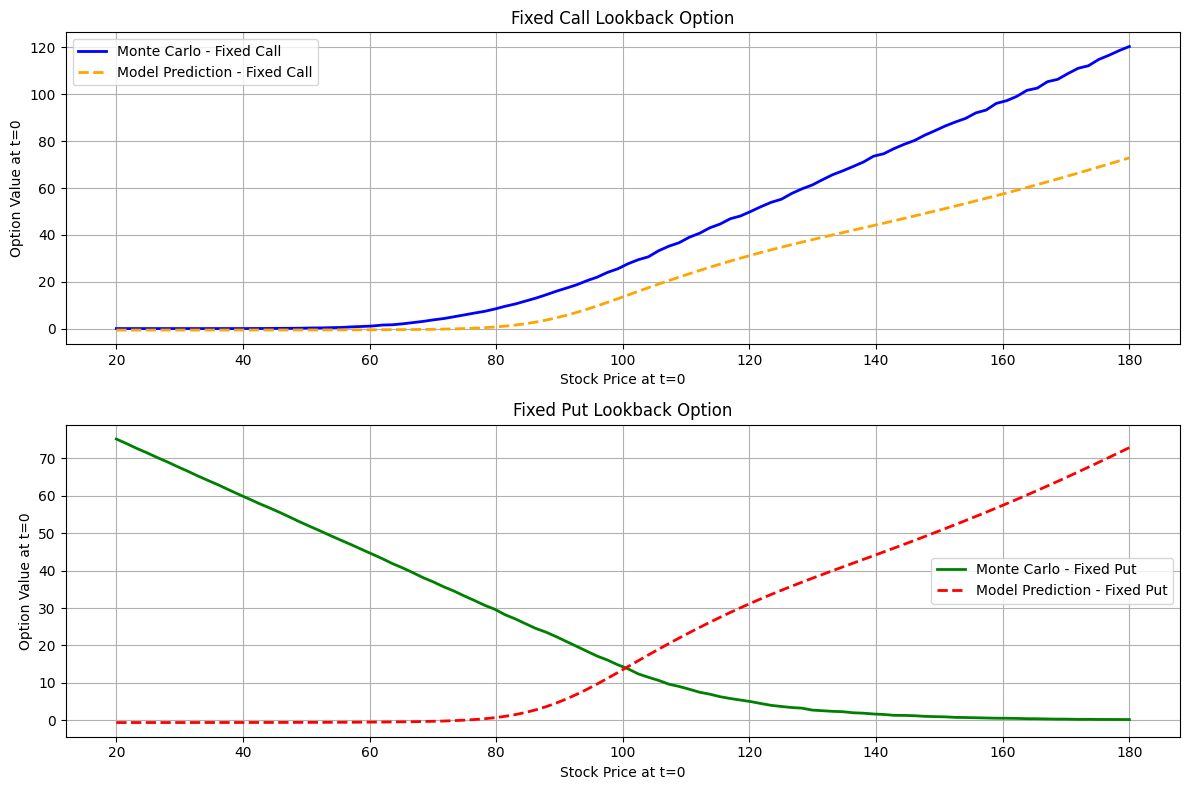

In [ ]:
# Parameters
T = tf.constant(2.0, dtype=DTYPE)  # Maturity
r = tf.constant(0.05, dtype=DTYPE)  # Risk-free rate
sigma = tf.constant(0.2, dtype=DTYPE)  # Volatility
K = tf.constant(100.0, dtype=DTYPE)  # Strike price

# Generate a range of initial stock prices for plotting
S0_range = np.linspace(20, 180, 100)

# Store prices for Fixed Call and Fixed Put
call_mc_prices = []
call_model_prices = []
put_mc_prices = []
put_model_prices = []

# Compute Monte Carlo prices and model predictions for both Fixed Call and Fixed Put
for S0 in S0_range:
    # Monte Carlo Simulation
    call_price_mc = monte_carlo_simulation(S0, option_type='fixed_call')[0]
    put_price_mc = monte_carlo_simulation(S0, option_type='fixed_put')[0]
    call_mc_prices.append(call_price_mc)
    put_mc_prices.append(put_price_mc)

    # Model Prediction
    S_input = tf.constant([[S0]], dtype=DTYPE)
    t_input = tf.zeros_like(S_input)  # t=0 for prediction at the initial time
    M_input = tf.constant([[S0]], dtype=DTYPE)  # Assume M=S0 initially

    inputs = tf.concat([S_input, M_input, t_input], axis=1)

    call_price_model = model(inputs).numpy()[0, 0]  # Fixed Call prediction
    # Modify the model if needed for Fixed Put
    put_price_model = model(inputs).numpy()[0, 0]  # Fixed Put prediction (reuse the same model in this case)
    call_model_prices.append(call_price_model)
    put_model_prices.append(put_price_model)

# Plot graphs for Fixed Call and Fixed Put
plt.figure(figsize=(12, 8))

# Fixed Call
plt.subplot(2, 1, 1)
plt.plot(S0_range, call_mc_prices, label='Monte Carlo - Fixed Call', color='blue', linewidth=2)
plt.plot(S0_range, call_model_prices, label='Model Prediction - Fixed Call', color='orange', linestyle='--', linewidth=2)
plt.xlabel('Stock Price at t=0')
plt.ylabel('Option Value at t=0')
plt.title('Fixed Call Lookback Option')
plt.grid(True)
plt.legend()

# Fixed Put
plt.subplot(2, 1, 2)
plt.plot(S0_range, put_mc_prices, label='Monte Carlo - Fixed Put', color='green', linewidth=2)
plt.plot(S0_range, put_model_prices, label='Model Prediction - Fixed Put', color='red', linestyle='--', linewidth=2)
plt.xlabel('Stock Price at t=0')
plt.ylabel('Option Value at t=0')
plt.title('Fixed Put Lookback Option')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Set data type
DTYPE = 'float32'
tf.keras.backend.set_floatx(DTYPE)

# Parameters
T = tf.constant(2.0, dtype=DTYPE)  # Maturity time
r = tf.constant(0.05, dtype=DTYPE)  # Interest rate
sigma = tf.constant(0.2, dtype=DTYPE)  # Volatility
K = tf.constant(100.0, dtype=DTYPE)  # Strike price
a = tf.constant(75.0, dtype=DTYPE)  # Lower bound for asset price
b = tf.constant(125.0, dtype=DTYPE)  # Upper bound for asset price

# Payoff functions
def fixed_call_payoff(S_paths):
    max_S = tf.reduce_max(S_paths, axis=1, keepdims=True)
    payoff = tf.maximum(max_S - K, 0.0)
    return tf.tile(payoff, [1, S_paths.shape[1]])

def fixed_put_payoff(S_paths):
    min_S = tf.reduce_min(S_paths, axis=1, keepdims=True)
    payoff = tf.maximum(K - min_S, 0.0)
    return tf.tile(payoff, [1,S_paths.shape[1]])

def floating_call_payoff(S_paths):
    min_S = tf.reduce_min(S_paths, axis=1, keepdims=True)
    payoff = tf.maximum(S_paths[:, -1:] - min_S, 0.0)
    return tf.tile(payoff, [1, S_paths.shape[1]])

def floating_put_payoff(S_paths):
    max_S = tf.reduce_max(S_paths, axis=1, keepdims=True)
    payoff = tf.maximum(max_S - S_paths[:, -1:], 0.0)
    return tf.tile(payoff, [1, S_paths.shape[1]])

# Generate paths
def generate_paths(batch_size, time_steps):
    S0 = tf.random.uniform((batch_size, 1), minval=a, maxval=b, dtype=DTYPE)
    dt = T / time_steps
    paths = [S0]
    for _ in range(1, time_steps):
        dW = tf.random.normal((batch_size, 1), mean=0.0, stddev=tf.sqrt(dt), dtype=DTYPE)
        St = paths[-1] * tf.exp((r - 0.5 * sigma**2) * dt + sigma * dW)
        paths.append(St)
    return tf.concat(paths, axis=1)

# Define model
def init_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(3,)),
        tf.keras.layers.Dense(50, activation='tanh'),
        tf.keras.layers.Dense(50, activation='tanh'),
        tf.keras.layers.Dense(50, activation='tanh'),
        tf.keras.layers.Dense(1, activation=None)
    ])
    return model

# PDE and loss function
@tf.function
def loss_function(model, S, M, t, payoff, option_type):
    with tf.GradientTape(persistent=True) as tape:
        tape.watch([S, M, t])
        inputs = tf.concat([S, M, t], axis=1)
        u = model(inputs)

        # Compute gradients
        u_S = tape.gradient(u, S)
        u_M = tape.gradient(u, M)
        u_t = tape.gradient(u, t)

    # Second-order derivative w.r.t. S
    u_SS = tape.gradient(u_S, S)

    # PDE residual
    pde_residual = u_t + 0.5 * sigma**2 * S**2 * u_SS + r * S * u_S - r * u
    loss_pde = tf.reduce_mean(tf.square(pde_residual))

    # Payoff loss at t = T
    payoff = tf.reshape(payoff, (-1, 1))
    mask_payoff = tf.equal(t, T)
    loss_payoff = tf.reduce_mean(tf.boolean_mask(tf.square(u - payoff), mask_payoff))

    # Neumann boundary condition
    mask = tf.equal(M, S)
    u_M_at_mask = tf.boolean_mask(u_M, mask)
    loss_Neumann = tf.reduce_mean(tf.square(u_M_at_mask))

    # Total loss
    return loss_pde + loss_payoff + loss_Neumann

# Training loop
def train_pinn(model, payoff_function, option_type, epochs=5000, batch_size=2000, time_steps=100):
    optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
    for epoch in range(epochs):
        S_paths = generate_paths(batch_size, time_steps)
        t = tf.linspace(0.0, T, time_steps)
        t = tf.tile(t[tf.newaxis, :], [batch_size, 1])

        # Compute payoff
        payoff = payoff_function(S_paths)

        # Compute cumulative min or max for all option types
        M = tf.TensorArray(dtype=S_paths.dtype, size=S_paths.shape[1])

        current_value = S_paths[:, 0]
        M = M.write(0, current_value)

        for i in range(1, S_paths.shape[1]):
            if "Floating Call" in option_type or "Floating Put" in option_type:
                # Floating options: dynamic min or max
                if "Floating Call" in option_type:
                    current_value = tf.minimum(current_value, S_paths[:, i])  # Minimum for Floating Call
                elif "Floating Put" in option_type:
                    current_value = tf.maximum(current_value, S_paths[:, i])  # Maximum for Floating Put

            elif "Fixed Call" in option_type or "Fixed Put" in option_type:
                # Fixed options: constant min or max
                if "Fixed Call" in option_type:
                    current_value = tf.maximum(current_value, S_paths[:, i])  # Maximum for Fixed Put
                elif "Fixed Put" in option_type:
                    current_value = tf.minimum(current_value, S_paths[:, i])  # Minimum for Fixed Call

            M = M.write(i, current_value)

        M = M.stack()
        M = tf.transpose(M)

        # loss computation
        S = tf.reshape(S_paths, (-1, 1))
        t = tf.reshape(t, (-1, 1))
        M = tf.reshape(M, (-1, 1))
        with tf.GradientTape() as tape:
            loss = loss_function(model, S, M, t, payoff, option_type)
        gradients = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(gradients, model.trainable_variables))

        # Log loss every 100 epochs
        if epoch % 100 == 0 or epoch == epochs - 1:
            print(f"Epoch {epoch}, Loss: {loss.numpy()}")

# Train the model for each option type
cases = {"Fixed Call": fixed_call_payoff}
#"Fixed Put": fixed_put_payoff, "Floating Call": floating_call_payoff,"Floating Put": floating_put_payoff}

for case_name, payoff_function in cases.items():
    print(f"Training for {case_name}")
    model = init_model()
    train_pinn(model, payoff_function, option_type=case_name, epochs=20000, batch_size=1000, time_steps=50)
    print(f"Training completed for {case_name}")


Training for Fixed Call
Epoch 0, Loss: 1773.041748046875
Epoch 100, Loss: 1224.477783203125
Epoch 200, Loss: 1179.28759765625
Epoch 300, Loss: 913.0669555664062
Epoch 400, Loss: 980.2625122070312
Epoch 500, Loss: 785.8710327148438
Epoch 600, Loss: 666.647216796875
Epoch 700, Loss: 627.6469116210938
Epoch 800, Loss: 481.5460205078125
Epoch 900, Loss: 381.33258056640625
Epoch 1000, Loss: 422.48529052734375
Epoch 1100, Loss: 356.7264099121094
Epoch 1200, Loss: 269.4998474121094
Epoch 1300, Loss: 194.2852783203125
Epoch 1400, Loss: 255.79876708984375
Epoch 1500, Loss: 191.96917724609375
Epoch 1600, Loss: 176.2189178466797
Epoch 1700, Loss: 174.6492919921875
Epoch 1800, Loss: 207.60691833496094
Epoch 1900, Loss: 173.5853271484375
Epoch 2000, Loss: 113.28195190429688
Epoch 2100, Loss: 149.3997344970703
Epoch 2200, Loss: 95.59652709960938
Epoch 2300, Loss: 115.10167694091797
Epoch 2400, Loss: 112.1066665649414
Epoch 2500, Loss: 132.27395629882812
Epoch 2600, Loss: 75.74507141113281
Epoch 2700

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Set data type
DTYPE = 'float32'
tf.keras.backend.set_floatx(DTYPE)

# Parameters
T = tf.constant(2.0, dtype=DTYPE)  # Maturity time
r = tf.constant(0.05, dtype=DTYPE)  # Interest rate
sigma = tf.constant(0.2, dtype=DTYPE)  # Volatility
K = tf.constant(100.0, dtype=DTYPE)  # Strike price
a = tf.constant(75.0, dtype=DTYPE)  # Lower bound for asset price
b = tf.constant(125.0, dtype=DTYPE)  # Upper bound for asset price

# Payoff functions
def fixed_call_payoff(S_paths):
    max_S = tf.reduce_max(S_paths, axis=1, keepdims=True)
    payoff = tf.maximum(max_S - K, 0.0)
    return tf.tile(payoff, [1, S_paths.shape[1]])

def fixed_put_payoff(S_paths):
    min_S = tf.reduce_min(S_paths, axis=1, keepdims=True)
    payoff = tf.maximum(K - min_S, 0.0)
    return tf.tile(payoff, [1, S_paths.shape[1]])

def floating_call_payoff(S_paths):
    min_S = tf.reduce_min(S_paths, axis=1, keepdims=True)
    payoff = tf.maximum(S_paths[:, -1:] - min_S, 0.0)
    return tf.tile(payoff, [1, S_paths.shape[1]])

def floating_put_payoff(S_paths):
    max_S = tf.reduce_max(S_paths, axis=1, keepdims=True)
    payoff = tf.maximum(max_S - S_paths[:, -1:], 0.0)
    return tf.tile(payoff, [1, S_paths.shape[1]])

# Generate paths
def generate_paths(batch_size, time_steps):
    S0 = tf.random.uniform((batch_size, 1), minval=a, maxval=b, dtype=DTYPE)
    dt = T / time_steps
    paths = [S0]
    for _ in range(1, time_steps):
        dW = tf.random.normal((batch_size, 1), mean=0.0, stddev=tf.sqrt(dt), dtype=DTYPE)
        St = paths[-1] * tf.exp((r - 0.5 * sigma**2) * dt + sigma * dW)
        paths.append(St)
    return tf.concat(paths, axis=1)

# Define model
def init_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(3,)),
        tf.keras.layers.Dense(50, activation='tanh'),
        tf.keras.layers.Dense(50, activation='tanh'),
        tf.keras.layers.Dense(50, activation='tanh'),
        tf.keras.layers.Dense(1, activation=None)
    ])
    return model

# PDE and loss function
@tf.function
def loss_function(model, S, M, t, payoff):
    with tf.GradientTape(persistent=True) as tape:
        tape.watch([S, M, t])
        inputs = tf.concat([S, M, t], axis=1)
        u = model(inputs)

        # Compute gradients
        u_S = tape.gradient(u, S)
        u_M = tape.gradient(u, M)
        u_t = tape.gradient(u, t)

    # Second-order derivative w.r.t. S
    u_SS = tape.gradient(u_S, S)

    # PDE residual
    pde_residual = u_t + 0.5 * sigma**2 * S**2 * u_SS + r * S * u_S - r * u
    loss_pde = tf.reduce_mean(tf.square(pde_residual))

    # Payoff loss at t = T
    payoff = tf.reshape(payoff, (-1, 1))
    mask_payoff = tf.equal(t, T)
    loss_payoff = tf.reduce_mean(tf.boolean_mask(tf.square(u - payoff), mask_payoff))

    # Neumann boundary condition
    mask = tf.equal(M, S)
    u_M_at_mask = tf.boolean_mask(u_M, mask)
    loss_Neumann = tf.reduce_mean(tf.square(u_M_at_mask))

    # Total loss
    return loss_pde + loss_payoff + loss_Neumann

# Training loop
def train_pinn(model, payoff_function, epochs=10000, batch_size=2000, time_steps=100):
    optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)
    for epoch in range(epochs):
        S_paths = generate_paths(batch_size, time_steps)
        t = tf.linspace(0.0, T, time_steps)
        t = tf.tile(t[tf.newaxis, :], [batch_size, 1])

        # Compute payoff
        payoff = payoff_function(S_paths)

        # Compute cumulative min or max
        M = tf.TensorArray(dtype=S_paths.dtype, size=S_paths.shape[1])
        current_value = S_paths[:, 0]
        M = M.write(0, current_value)

        for i in range(1, S_paths.shape[1]):
            current_value = tf.minimum(current_value, S_paths[:, i])
            M = M.write(i, current_value)

        M = M.stack()
        M = tf.transpose(M)

        # loss computation
        S = tf.reshape(S_paths, (-1, 1))
        t = tf.reshape(t, (-1, 1))
        M = tf.reshape(M, (-1, 1))
        with tf.GradientTape() as tape:
            loss = loss_function(model, S, M, t, payoff)
        gradients = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(gradients, model.trainable_variables))

        # Log loss every 100 epochs
        if epoch % 100 == 0 or epoch == epochs - 1:
            print(f"Epoch {epoch}, Loss: {loss.numpy()}")

# Monte Carlo simulation
def monte_carlo_simulation(S0, payoff_function, time_steps=50, n_paths=10000):
    dt = T / time_steps
    paths = [tf.constant(S0, shape=(n_paths, 1), dtype=DTYPE)]
    for _ in range(1, time_steps):
        dW = tf.random.normal((n_paths, 1), mean=0.0, stddev=tf.sqrt(dt), dtype=DTYPE)
        St = paths[-1] * tf.exp((r - 0.5 * sigma**2) * dt + sigma * dW)
        paths.append(St)
    paths = tf.concat(paths, axis=1)
    payoff = payoff_function(paths)
    return tf.reduce_mean(payoff[:, -1]).numpy()

# Train and compare PINN with Monte Carlo
option_types = {
    "Fixed Call": fixed_call_payoff,
    "Fixed Put": fixed_put_payoff,
    "Floating Call": floating_call_payoff,
    "Floating Put": floating_put_payoff
}

S0_range = np.linspace(20, 180, 50)
results = {}
monte_carlo_results = {}

for option_type, payoff_function in option_types.items():
    print(f"Training {option_type}...")
    model = init_model()
    train_pinn(model, payoff_function, epochs=15000, batch_size=1000, time_steps=50)
    print(f"Training completed for {option_type}")

    # Predict option prices using PINN
    pinn_prices = []
    monte_carlo_prices = []
    for S0 in S0_range:
        # PINN prediction
        S_input = tf.constant([[S0]], dtype=DTYPE)
        t_input = tf.zeros_like(S_input)
        M_input = tf.constant([[S0]], dtype=DTYPE)
        inputs = tf.concat([S_input, M_input, t_input], axis=1)
        pinn_price = model(inputs).numpy()[0, 0]
        pinn_prices.append(pinn_price)

        # Monte Carlo simulation
        mc_price = monte_carlo_simulation(S0, payoff_function)
        monte_carlo_prices.append(mc_price)

    results[option_type] = pinn_prices
    monte_carlo_results[option_type] = monte_carlo_prices



Training Fixed Call...


Epoch 0, Loss: 1895.3515625
Epoch 100, Loss: 1467.3060302734375
Epoch 200, Loss: 1374.746826171875
Epoch 300, Loss: 1196.4737548828125
Epoch 400, Loss: 1309.3095703125
Epoch 500, Loss: 1246.9134521484375
Epoch 600, Loss: 1140.7447509765625
Epoch 700, Loss: 1211.3734130859375
Epoch 800, Loss: 1165.156982421875
Epoch 900, Loss: 1102.4248046875
Epoch 1000, Loss: 1064.9588623046875
Epoch 1100, Loss: 1259.7440185546875
Epoch 1200, Loss: 1117.458740234375
Epoch 1300, Loss: 1103.9000244140625
Epoch 1400, Loss: 1019.7313232421875
Epoch 1500, Loss: 1111.32080078125
Epoch 1600, Loss: 1141.7032470703125
Epoch 1700, Loss: 1090.7293701171875
Epoch 1800, Loss: 1071.333251953125
Epoch 1900, Loss: 1166.61376953125
Epoch 2000, Loss: 1033.8438720703125
Epoch 2100, Loss: 973.8717651367188
Epoch 2200, Loss: 882.55126953125
Epoch 2300, Loss: 996.4708251953125
Epoch 2400, Loss: 862.162109375
Epoch 2500, Loss: 862.9159545898438
Epoch 2600, Loss: 940.5572509765625
Epoch 2700, Loss: 806.5901489257812
Epoch 280